In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
# load the dataset
data = pd.read_csv('../data/diabetes_large_dataset.csv')

In [5]:
data[:5]

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


In [6]:
#copy the dataset
df = data.copy()
df[:5]

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


In [7]:
df.shape

(100000, 209)

In [8]:
df.columns

Index(['patient_id', 'record_id', 'age', 'age_group', 'sex', 'gender',
       'ethnicity', 'race_group', 'marital_status', 'education_level',
       ...
       'diabetes_risk_score', 'overall_health_score', 'physical_health_score',
       'mental_wellbeing_score', 'quality_of_life_score',
       'chronic_condition_count', 'hospitalization_history',
       'emergency_visit_history', 'diabetes_status', 'diabetes_type'],
      dtype='str', length=209)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 209 entries, patient_id to diabetes_type
dtypes: float64(102), int64(15), str(92)
memory usage: 159.5 MB


##### Missing value analysis on entire datasset

In [10]:
# missing value analysis
missing_value_count = df.isnull().sum()

In [11]:
#missing value counts grater than zero
missing_counts = missing_value_count[missing_value_count>0]

In [12]:
#missing value percentage
missing_value_per = ((missing_counts)/len(df)*100)
missing_value_per

age                              1.993
sex                              2.005
height_cm                        4.957
weight_kg                        4.929
bmi                              2.022
waist_circumference_cm           5.120
hip_circumference_cm             5.003
fasting_glucose_mg_dl            2.061
hba1c_percent                    1.946
fasting_insulin_uIU_ml          10.178
c_peptide_ng_ml                  9.948
systolic_bp                      1.947
diastolic_bp                     2.094
pulse_pressure                   0.018
total_cholesterol_mg_dl          5.019
ldl_mg_dl                        5.001
hdl_mg_dl                        4.956
triglycerides_mg_dl              5.045
creatinine_mg_dl                 4.985
egfr_ml_min_1_73m2               5.027
urine_albumin_mg_g              10.134
alt_u_l                          5.000
ast_u_l                          5.044
hemoglobin_g_dl                  5.102
wbc_count                        5.040
platelet_count           

In [13]:
df['diabetes_status'].value_counts()

diabetes_status
0.0    70573
1.0    27407
Name: count, dtype: int64

In [14]:
df['diabetes_status'].isnull().sum()

np.int64(2020)

In [15]:
#remove null value rows in the target column
df_clean = df.dropna(subset =['diabetes_status']).copy()

In [16]:
df_clean['diabetes_status'].isnull().sum()


np.int64(0)

In [17]:
# reduce the no. of rows to 20000
from sklearn.model_selection import train_test_split

sample_df, remaining_df = train_test_split(
    df_clean,
    train_size = 20000,
    stratify = df_clean['diabetes_status'],
    random_state = 42
)

In [18]:
sample_df.shape

(20000, 209)

In [19]:
count = sample_df['diabetes_status'].value_counts()
count

diabetes_status
0.0    14406
1.0     5594
Name: count, dtype: int64

In [20]:
per = ((count)/len(sample_df)*100)
per

diabetes_status
0.0    72.03
1.0    27.97
Name: count, dtype: float64

In [21]:
counts = sample_df.isnull().sum()

In [22]:
missing_counts = counts[counts>0]

In [23]:
len(missing_counts)

42

In [24]:
per_missing_counts = ((missing_counts)/len(sample_df)*100)

In [25]:
#create a summary of columns containing missing values
missing_summary = pd.DataFrame({
    'Missing_count' : missing_counts,
    'Missing_Percentage' : per_missing_counts
})

#sort by missing percentage
missing_summary = missing_summary.sort_values(
    by = 'Missing_Percentage', ascending = False
)
missing_summary

,Missing_count,Missing_Percentage
age_at_menopause,16515,82.575
self_management_score,2073,10.365
fasting_insulin_uIU_ml,2052,10.260
folate_ng_ml,2047,10.235
vitamin_d_ng_ml,2045,10.225
vitamin_b12_pg_ml,2043,10.215
c_peptide_ng_ml,2040,10.200
medication_adherence_percent,2018,10.090
urine_albumin_mg_g,2014,10.070
ferritin_ng_ml,1981,9.905


In [26]:
#column with maximum percentage:
missing_summary.head(1)

,Missing_count,Missing_Percentage
age_at_menopause,16515,82.575


In [27]:
#column with minimum percentage:
missing_summary.tail(1)

,Missing_count,Missing_Percentage
pulse_pressure,4,0.02


In [28]:
#columns with more than 50% missing value
missing_summary[missing_summary['Missing_Percentage'] > 50]

,Missing_count,Missing_Percentage
age_at_menopause,16515,82.575


In [29]:

col_list = list(sample_df.columns)


print(', '.join(col_list))

patient_id, record_id, age, age_group, sex, gender, ethnicity, race_group, marital_status, education_level, employment_status, occupation_category, income_level, annual_income, household_size, dependents, residential_area_type, urban_rural, insurance_status, height_cm, weight_kg, bmi, bmi_category, waist_circumference_cm, hip_circumference_cm, waist_to_hip_ratio, body_fat_percentage, lean_body_mass_kg, body_surface_area, resting_metabolic_rate, fasting_glucose_mg_dl, random_glucose_mg_dl, post_meal_glucose_mg_dl, two_hour_glucose_mg_dl, glucose_variability, hba1c_percent, estimated_average_glucose_mg_dl, fasting_insulin_uIU_ml, c_peptide_ng_ml, insulin_resistance_index, systolic_bp, diastolic_bp, pulse_pressure, mean_arterial_pressure, heart_rate, resting_heart_rate, hypertension_status, total_cholesterol_mg_dl, ldl_mg_dl, hdl_mg_dl, triglycerides_mg_dl, vldl_mg_dl, cholesterol_hdl_ratio, non_hdl_cholesterol, creatinine_mg_dl, bun_mg_dl, egfr_ml_min_1_73m2, urine_albumin_mg_g, urine_al

In [30]:
sample_df.dtypes

patient_id                     str
record_id                      str
age                        float64
age_group                      str
sex                            str
                            ...   
chronic_condition_count      int64
hospitalization_history        str
emergency_visit_history        str
diabetes_status            float64
diabetes_type                  str
Length: 209, dtype: object

In [31]:

numeric_cols =sample_df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = sample_df.select_dtypes(include=["str"]).columns

In [32]:
print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols )

Numerical columns: Index(['age', 'annual_income', 'household_size', 'dependents', 'height_cm',
       'weight_kg', 'bmi', 'waist_circumference_cm', 'hip_circumference_cm',
       'waist_to_hip_ratio',
       ...
       'obesity_risk_score', 'hypertension_risk_score', 'kidney_risk_score',
       'diabetes_risk_score', 'overall_health_score', 'physical_health_score',
       'mental_wellbeing_score', 'quality_of_life_score',
       'chronic_condition_count', 'diabetes_status'],
      dtype='str', length=117)
Categorical columns: Index(['patient_id', 'record_id', 'age_group', 'sex', 'gender', 'ethnicity',
       'race_group', 'marital_status', 'education_level', 'employment_status',
       'occupation_category', 'income_level', 'residential_area_type',
       'urban_rural', 'insurance_status', 'bmi_category',
       'hypertension_status', 'proteinuria_status', 'kidney_disease_status',
       'fatty_liver_status', 'family_history_diabetes', 'father_diabetes',
       'mother_diabetes', 'sibl

In [33]:
print("No. of numerical columns:", len(numeric_cols))
print("No. of catregorical columns:", len(categorical_cols))

No. of numerical columns: 117
No. of catregorical columns: 92


In [34]:
#checking identifiers
print("Patient ID unique values:", sample_df['patient_id'].nunique())
print("Record ID unique values:", sample_df['record_id'].nunique())
print("Total rows:", len(sample_df))

Patient ID unique values: 20000
Record ID unique values: 20000
Total rows: 20000


In [35]:
df1 = sample_df.copy()
df1.head(10)

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
47437,P047438,R00047438,39.0,31-40,Male,Male,Black,Black,Single,Less than High School,...,0.0,79.4,79.7,68.6,71.3,1,3,0,0.0,No Diabetes
50216,P050217,R00050217,43.0,41-50,Female,Female,White,White,Single,Some College,...,0.0,71.8,68.3,75.5,67.7,1,0,0,0.0,No Diabetes
89362,P089363,R00089363,52.0,51-60,Male,Male,White,White,Married,Less than High School,...,0.0,97.4,100.0,47.6,82.9,2,0,1,0.0,No Diabetes
8812,P008813,R00008813,51.0,51-60,Female,Female,White,White,Married,Bachelor,...,18.8,59.0,59.1,50.7,74.2,2,0,0,1.0,Type 2
67986,P067987,R00067987,56.0,51-60,Female,Female,White,White,Married,Master,...,31.5,59.7,56.0,79.6,83.0,7,0,0,1.0,Type 2
28051,P028052,R00028052,64.0,61-70,Female,Female,Asian,Asian,Single,High School,...,2.5,79.3,74.6,61.9,80.3,3,0,2,0.0,No Diabetes
83822,P083823,R00083823,44.0,41-50,Female,Female,Asian,Asian,Single,Less than High School,...,7.0,73.2,70.7,76.4,85.2,1,0,0,0.0,No Diabetes
11283,P011284,R00011284,44.0,41-50,Female,Female,White,White,Married,Some College,...,0.9,79.5,78.2,70.8,86.9,1,0,1,0.0,No Diabetes
34170,P034171,R00034171,49.0,41-50,Male,Male,White,White,Married,Some College,...,NaN,78.7,89.4,60.9,73.6,1,0,2,0.0,No Diabetes
7446,P007447,R00007447,61.0,61-70,Female,Female,White,White,Divorced,High School,...,0.0,72.4,74.0,29.2,52.9,3,0,0,0.0,No Diabetes


In [36]:
feature_info = pd. DataFrame({
    'Column': df1.columns,
    'Data_Types': df1.dtypes.values,
    'Missing_percentage': df1.isnull().mean().values * 100,
    'Unique_Values': df1.nunique().values
})
feature_info.head(40)

,Column,Data_Types,Missing_percentage,Unique_Values
0,patient_id,str,0.000,20000
1,record_id,str,0.000,20000
2,age,float64,2.015,73
3,age_group,str,0.000,6
4,sex,str,2.035,2
5,gender,str,0.000,3
6,ethnicity,str,0.000,8
7,race_group,str,0.000,8
8,marital_status,str,0.000,4
9,education_level,str,0.000,6


In [37]:
# Search for relevant health-related features

keywords = [
    'age', 'sex', 'gender', 'bmi', 'height', 'weight', 'waist', 'hip', 'body_fat', 'glucose', 'hba1c', 'blood_pressure', 'family_history',
    'physical_activity', 'smoking', 'diet'
]

for word in keywords:
    matches = [
        col for col in sample_df.columns
        if word.lower() in col.lower()
    ]

    if matches:
        print(f"\n{word.upper()}:")
        print(matches)


AGE:
['age', 'age_group', 'body_fat_percentage', 'estimated_average_glucose_mg_dl', 'self_management_score', 'age_at_menopause']

SEX:
['sex']

GENDER:
['gender']

BMI:
['bmi', 'bmi_category']

HEIGHT:
['height_cm']

WEIGHT:
['weight_kg']

WAIST:
['waist_circumference_cm', 'waist_to_hip_ratio']

HIP:
['hip_circumference_cm', 'waist_to_hip_ratio']

BODY_FAT:
['body_fat_percentage']

GLUCOSE:
['fasting_glucose_mg_dl', 'random_glucose_mg_dl', 'post_meal_glucose_mg_dl', 'two_hour_glucose_mg_dl', 'glucose_variability', 'estimated_average_glucose_mg_dl', 'glucose_monitoring_frequency', 'home_glucose_monitoring', 'continuous_glucose_monitor']

HBA1C:
['hba1c_percent']

BLOOD_PRESSURE:
['blood_pressure_medication']

FAMILY_HISTORY:
['family_history_diabetes', 'family_history_cardiovascular_disease', 'family_history_hypertension', 'family_history_obesity']

PHYSICAL_ACTIVITY:
['physical_activity_level']

SMOKING:
['smoking_status', 'smoking_frequency']

DIET:
['diet_quality_score', 'diet_patte

In [38]:
df1['diabetes_status'].nunique()

2

In [39]:
df1['diabetes_status'].value_counts()

diabetes_status
0.0    14406
1.0     5594
Name: count, dtype: int64

In [40]:
# removal of identifiers column
df1.drop(columns=['patient_id','record_id'], inplace= True)

In [41]:
df1.shape

(20000, 207)

In [42]:
pd.crosstab(df1['diabetes_type'], df1['diabetes_status'])

diabetes_status,0.0,1.0
diabetes_type,,
Gestational Diabetes,0,24
No Diabetes,14406,0
Other Diabetes,0,429
Type 1,0,1
Type 2,0,5031


In [43]:
# this shows that there is a need for removal of diabetes_type due to data leakage
df1.drop('diabetes_type',axis = 1, inplace= True)

In [44]:
df1.shape

(20000, 206)

In [45]:
df1.groupby('diabetes_status')['diabetes_risk_score'].describe()

,count,mean,std,min,25%,50%,75%,max
diabetes_status,,,,,,,,
0.0,14105.0,4.493563,4.850287,0.0,0.0,3.10,7.4,26.5
1.0,5488.0,28.513812,18.577241,0.0,15.9,22.55,35.0,100.0


In [46]:
pd.crosstab(df1['diabetes_status'], df1['diabetes_risk_score'])


diabetes_risk_score,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,97.7,98.4,98.8,98.9,99.1,99.2,99.6,99.7,99.9,100.0
diabetes_status,,,,,,,,,,,,,,,,,,,,,
0.0,4193,82,88,100,91,99,100,92,89,91,...,0,0,0,0,0,0,0,0,0,0
1.0,3,0,0,0,0,1,1,0,0,3,...,1,1,1,1,2,1,1,1,1,14


In [47]:
df1.drop('diabetes_risk_score',axis = 1, inplace= True)

In [48]:
df1.shape

(20000, 205)

In [49]:
col_list = list(df1.columns)
print(', '.join(col_list))

age, age_group, sex, gender, ethnicity, race_group, marital_status, education_level, employment_status, occupation_category, income_level, annual_income, household_size, dependents, residential_area_type, urban_rural, insurance_status, height_cm, weight_kg, bmi, bmi_category, waist_circumference_cm, hip_circumference_cm, waist_to_hip_ratio, body_fat_percentage, lean_body_mass_kg, body_surface_area, resting_metabolic_rate, fasting_glucose_mg_dl, random_glucose_mg_dl, post_meal_glucose_mg_dl, two_hour_glucose_mg_dl, glucose_variability, hba1c_percent, estimated_average_glucose_mg_dl, fasting_insulin_uIU_ml, c_peptide_ng_ml, insulin_resistance_index, systolic_bp, diastolic_bp, pulse_pressure, mean_arterial_pressure, heart_rate, resting_heart_rate, hypertension_status, total_cholesterol_mg_dl, ldl_mg_dl, hdl_mg_dl, triglycerides_mg_dl, vldl_mg_dl, cholesterol_hdl_ratio, non_hdl_cholesterol, creatinine_mg_dl, bun_mg_dl, egfr_ml_min_1_73m2, urine_albumin_mg_g, urine_albumin_creatinine_ratio,

#### Feature selection

In [50]:
column_lst = ['age_group', 'gender','bmi', 'waist_circumference_cm', 'family_history_diabetes', 'family_history_obesity', 'family_history_hypertension',
             'physical_activity_level', 'exercise_days_per_week', 'sedentary_hours_per_day', 'smoking_status', 'sleep_hours', 'stress_level', 
             'diet_quality_score', 'added_sugar_grams_per_day', 'fiber_grams_per_day', 'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp',
             'triglycerides_mg_dl', 'diabetes_status']

In [51]:
df2 = df1[column_lst]
df2.head()

,age_group,gender,bmi,waist_circumference_cm,family_history_diabetes,family_history_obesity,family_history_hypertension,physical_activity_level,exercise_days_per_week,sedentary_hours_per_day,...,sleep_hours,stress_level,diet_quality_score,added_sugar_grams_per_day,fiber_grams_per_day,fruit_servings_per_day,systolic_bp,diastolic_bp,triglycerides_mg_dl,diabetes_status
47437,31-40,Male,27.25,96.3,No,No,No,Extremely Active,7,6.6,...,6.3,Low,57.0,55.6,23.8,3.5,118.0,67.0,215.0,0.0
50216,41-50,Female,31.47,88.5,Yes,No,Yes,Lightly Active,1,8.2,...,8.4,Moderate,51.3,79.3,4.5,1.4,118.0,80.0,203.2,0.0
89362,51-60,Male,23.58,93.6,Yes,No,No,Lightly Active,1,5.4,...,5.1,Low,53.1,75.6,9.0,0.0,118.0,81.0,121.6,0.0
8812,51-60,Female,23.62,71.3,Yes,No,Yes,Sedentary,1,6.2,...,6.1,High,53.8,30.1,11.5,3.3,120.0,83.0,106.5,1.0
67986,51-60,Female,32.51,81.2,Yes,No,Yes,Lightly Active,0,6.2,...,6.7,Moderate,57.2,76.8,17.9,2.3,153.0,76.0,174.8,1.0


In [52]:
df2.shape

(20000, 21)

In [53]:
df2.columns

Index(['age_group', 'gender', 'bmi', 'waist_circumference_cm',
       'family_history_diabetes', 'family_history_obesity',
       'family_history_hypertension', 'physical_activity_level',
       'exercise_days_per_week', 'sedentary_hours_per_day', 'smoking_status',
       'sleep_hours', 'stress_level', 'diet_quality_score',
       'added_sugar_grams_per_day', 'fiber_grams_per_day',
       'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp',
       'triglycerides_mg_dl', 'diabetes_status'],
      dtype='str')

##### Missing value handling

In [54]:
count = df2.isnull().sum()

In [55]:
missing_counts1 = count[count>0]

In [56]:
len(missing_counts1)

10

In [57]:
per_missing_counts1 = ((missing_counts1)/len(df2)*100)

In [58]:
# summary of missing values
missing_value_summary = pd.DataFrame({
    'Missing_count' : missing_counts1,
    'Missing_Percentage' : per_missing_counts1
})

missing_value_summary = missing_value_summary.sort_values(
    by = 'Missing_Percentage', ascending = False
)
missing_value_summary

,Missing_count,Missing_Percentage
triglycerides_mg_dl,1070,5.350
smoking_status,1062,5.310
waist_circumference_cm,1030,5.150
sleep_hours,1008,5.040
diet_quality_score,992,4.960
physical_activity_level,986,4.930
stress_level,972,4.860
diastolic_bp,408,2.040
systolic_bp,399,1.995
bmi,382,1.910


In [59]:
missing_cols = df2.columns[df2.isnull().any()]
df2[missing_cols].dtypes

bmi                        float64
waist_circumference_cm     float64
physical_activity_level        str
smoking_status                 str
sleep_hours                float64
stress_level                   str
diet_quality_score         float64
systolic_bp                float64
diastolic_bp               float64
triglycerides_mg_dl        float64
dtype: object

In [60]:
numeric_cols1 =df2.select_dtypes(include=["int64", "float64"]).columns.drop('diabetes_status').tolist()
categorical_cols1 =  df2.select_dtypes(include=["str"]).columns

In [61]:
print('Numerical Columns:', numeric_cols1)
print('Categorical Columns:', categorical_cols1)


Numerical Columns: ['bmi', 'waist_circumference_cm', 'exercise_days_per_week', 'sedentary_hours_per_day', 'sleep_hours', 'diet_quality_score', 'added_sugar_grams_per_day', 'fiber_grams_per_day', 'fruit_servings_per_day', 'systolic_bp', 'diastolic_bp', 'triglycerides_mg_dl']
Categorical Columns: Index(['age_group', 'gender', 'family_history_diabetes',
       'family_history_obesity', 'family_history_hypertension',
       'physical_activity_level', 'smoking_status', 'stress_level'],
      dtype='str')


In [62]:
# null value handling using median and mode
for cols in numeric_cols1:
    df2[cols] = df2[cols].fillna(df2[cols].median())

In [63]:
for cols in categorical_cols1:
    df2[cols] = df2[cols].fillna(df2[cols].mode()[0])

In [64]:
df2.isnull().sum()

age_group                      0
gender                         0
bmi                            0
waist_circumference_cm         0
family_history_diabetes        0
family_history_obesity         0
family_history_hypertension    0
physical_activity_level        0
exercise_days_per_week         0
sedentary_hours_per_day        0
smoking_status                 0
sleep_hours                    0
stress_level                   0
diet_quality_score             0
added_sugar_grams_per_day      0
fiber_grams_per_day            0
fruit_servings_per_day         0
systolic_bp                    0
diastolic_bp                   0
triglycerides_mg_dl            0
diabetes_status                0
dtype: int64

In [65]:
# to check any duplicated rows
df2.duplicated().sum()

np.int64(0)

##### this tell no duplicate rows
#### Outlier Analysis

In [66]:
# box plots
import seaborn as sns

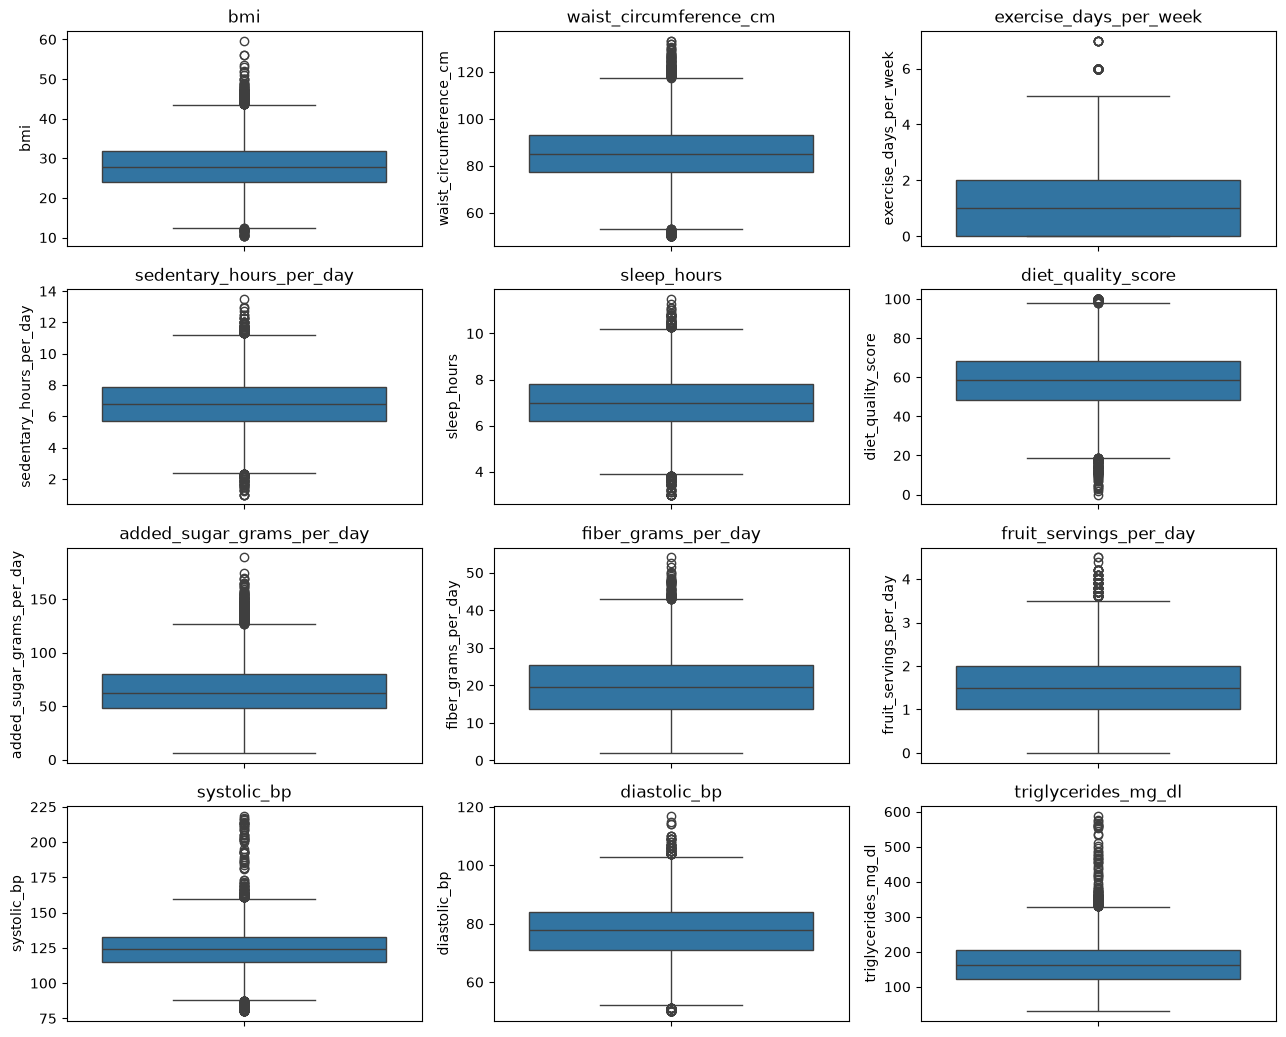

In [67]:
plt.figure(figsize = (13,13)) #canvas size
for i, col in enumerate(numeric_cols1, 1):
    plt.subplot(5, 3, i) # 5 rows, 3 columns
    sns.boxplot(y = df2[col])
    plt.title(col)

plt.tight_layout()  #prevent overlapping
plt.show()

In [68]:
# analysis of outliers using IQR method

outlier_results = []

for cols in numeric_cols1:
    Q1 = df2[cols].quantile(0.25)
    Q3 = df2[cols].quantile(0.75)
    IQR = Q3 - Q1

    lb = Q1 - (1.5 * IQR) #lower bound
    ub = Q3 + (1.5 * IQR) #upper bound

    outliers = df2[(df2[cols] < lb) | (df2[cols] > ub)] #filtering the outliers
    outlier_cnt = len(outliers) # no. of outliers in each column
    outlier_per = (outlier_cnt/len(df2)*100) # percentage of outlier

    outlier_results.append({
        'Feature': cols,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower bound': lb,
        'Upper bound': ub,
        'Outlier count': outlier_cnt,
        'Outlier per': outlier_per
    })
# to convert this to table
outlier_df = pd.DataFrame(outlier_results)
outlier_df

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier per
0,bmi,24.03,31.84,7.81,12.315,43.555,158,0.790
1,waist_circumference_cm,77.20,93.30,16.10,53.050,117.450,209,1.045
2,exercise_days_per_week,0.00,2.00,2.00,-3.000,5.000,94,0.470
3,sedentary_hours_per_day,5.70,7.90,2.20,2.400,11.200,123,0.615
4,sleep_hours,6.20,7.80,1.60,3.800,10.200,137,0.685
5,diet_quality_score,48.50,68.30,19.80,18.800,98.000,213,1.065
6,added_sugar_grams_per_day,48.20,79.70,31.50,0.950,126.950,288,1.440
7,fiber_grams_per_day,13.80,25.50,11.70,-3.750,43.050,65,0.325
8,fruit_servings_per_day,1.00,2.00,1.00,-0.500,3.500,97,0.485
9,systolic_bp,115.00,133.00,18.00,88.000,160.000,204,1.020


In [74]:
outlier_check = []
for cols in numeric_cols1:
    mini = df2[cols].min()
    maxi = df2[cols].max()
    uni_val = sorted(df2[cols].unique())[:20]
    
    outlier_check.append({
        'Feature': cols,
        'Minimum': mini,
        'Maximum': maxi,
        'Unique values': uni_val
    })
outlier_df = pd.DataFrame(outlier_check)
outlier_df

,Feature,Minimum,Maximum,Unique values
0,bmi,10.32,59.692509,"[10.32, 10.35, 10.44, 10.48, 10.62, 10.74, 10...."
1,waist_circumference_cm,50.00,133.300000,"[50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50...."
2,exercise_days_per_week,0.00,7.000000,"[0, 1, 2, 3, 4, 5, 6, 7]"
3,sedentary_hours_per_day,1.00,13.500000,"[1.0, 1.2, 1.3, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, ..."
4,sleep_hours,3.00,11.500000,"[3.0, 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8, ..."
5,diet_quality_score,0.00,100.000000,"[0.0, 1.7, 2.7, 3.2, 3.7, 4.6, 4.7, 4.8, 6.9, ..."
6,added_sugar_grams_per_day,6.30,189.000000,"[6.3, 10.2, 10.4, 10.6, 11.1, 11.8, 12.5, 12.8..."
7,fiber_grams_per_day,2.00,54.100000,"[2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.6, 2.7, 2.8, ..."
8,fruit_servings_per_day,0.00,4.500000,"[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."
9,systolic_bp,80.00,218.739617,"[80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87...."


In [71]:
outlier_check = []
for cols in numeric_cols1:
    print("Feature:", {cols})
    print("Minimum:", df2[cols].min())
    print("Maximum:", df2[cols].max())
    print("Unique values:", sorted(df2[cols].unique())[:20])
    
    

Feature: {'exercise_days_per_week'}
Minimum: 0
Maximum: 7
Unique values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Feature: {'added_sugar_grams_per_day'}
Minimum: 6.3
Maximum: 189.0
Unique values: [np.float64(6.3), np.float64(10.2), np.float64(10.4), np.float64(10.6), np.float64(11.1), np.float64(11.8), np.float64(12.5), np.float64(12.8), np.float64(12.9), np.float64(13.0), np.float64(13.1), np.float64(13.3), np.float64(13.4), np.float64(13.7), np.float64(13.8), np.float64(14.1), np.float64(14.7), np.float64(14.8), np.float64(15.1), np.float64(15.3)]
Feature: {'fruit_servings_per_day'}
Minimum: 0.0
Maximum: 4.5
Unique values: [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9), np.float64(1.0), np.float64(1.1), np.float64(1.2), np.float64(1.3), np.float64(1.4), np.float64(1.5), np.float64(1.6), np.float64(1.

#### Outlier treatment
##### Outliers were identified using the Interquartile Range (IQR) method. The analysis showed a relatively small proportion of potential outliers across the numerical features. These observations were further examined using their minimum and maximum values. Since the extreme values appeared potentially valid and no clear evidence of data-entry errors was identified, the observations were retained without removal or capping to preserve the original data distribution.
